# Stream B — `lora_stage2.ipynb`

**Purpose:** Cross-domain adaptation — fine-tune the Stage 1 head on VERITE + MMFakeBench
to improve OOD generalisation, then extract final Stream B features for all datasets.

**Why the encoder-LoRA approach was abandoned:**
- Full CLIP encoder forward+backward on 8 000 images × 10 epochs = hours on RTX 4060 Ti
- NC images are unavailable, so encoder fine-tuning on MMFake alone destroys NC performance
- Correct approach: pre-extract all OOD embeddings once (~2 min), then train head only (~1 min)

**Stage 2 strategy:**
1. Load Stage 1 head weights (`best_stage1.pt`)
2. One-time CLIP encode of VERITE + MMFakeBench → cached to `cache/lora_stage2/`
3. Fine-tune head on combined OOD data with low LR (preserves NC knowledge)
4. Validate on MMFake 20% hold-out; early-stop on AUROC
5. Extract final 256-d penultimate features for NC + VERITE + MMFakeBench → fusion input

**Expected runtime: < 5 minutes total**

## 0. Environment Check

In [14]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"PyTorch: {torch.__version__}")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB
PyTorch: 2.6.0+cu124


## 1. Imports & Paths

In [15]:
import os, sys, json, pickle, math
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import clip

# ── Project root ──────────────────────────────────────────────────────────────
try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

STREAM_B_DIR = ROOT / 'cache' / 'stream_b_features'
LORA1_DIR    = ROOT / 'cache' / 'lora_stage1'
LORA2_DIR    = ROOT / 'cache' / 'lora_stage2'
LORA2_DIR.mkdir(parents=True, exist_ok=True)

MMFAKE_JSON = ROOT / 'data' / 'mmfakebench' / 'MMFakeBench_test.json'
MMFAKE_ROOT = ROOT / 'data' / 'mmfakebench' / 'MMFakeBench_test'
VERITE_CSV  = ROOT / 'data' / 'verite' / 'image-text-verification' / 'VERITE' / 'VERITE.csv'
VERITE_IMGS = ROOT / 'data' / 'verite' / 'image-text-verification' / 'VERITE' / 'images'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# Verify Stage 1 outputs
for name in ('best_stage1.pt', 'lora1_feats_train.pkl', 'lora1_feats_val.pkl',
             'lora1_feats_test.pkl', 'lora1_feats_verite.pkl', 'lora1_feats_mmfake.pkl'):
    p = LORA1_DIR / name
    print(f"  {'✅' if p.exists() else '❌ MISSING'} {name}")

Project root: e:\eve-rag
Device: cuda
  ✅ best_stage1.pt
  ✅ lora1_feats_train.pkl
  ✅ lora1_feats_val.pkl
  ✅ lora1_feats_test.pkl
  ✅ lora1_feats_verite.pkl
  ✅ lora1_feats_mmfake.pkl


## 2. Rebuild Stage 1 Model & Load Weights

In [16]:
class LoRALinear(nn.Module):
    """Identical to Stage 1. All ops float32."""
    def __init__(self, in_features, out_features, rank=8, alpha=16.0, bias=True):
        super().__init__()
        self.rank  = rank
        self.scale = alpha / rank
        self.weight = nn.Parameter(torch.empty(out_features, in_features, dtype=torch.float32))
        self.bias   = nn.Parameter(torch.zeros(out_features, dtype=torch.float32)) if bias else None
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            bound = 1 / math.sqrt(in_features)
            nn.init.uniform_(self.bias, -bound, bound)
        self.lora_A = nn.Parameter(torch.empty(rank, in_features,  dtype=torch.float32))
        self.lora_B = nn.Parameter(torch.zeros(out_features, rank, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        x32  = x.float()
        base = F.linear(x32, self.weight, self.bias)
        lora = F.linear(F.linear(x32, self.lora_A), self.lora_B) * self.scale
        return base + lora


class CLIPLoRAClassifier(nn.Module):
    """Stage 1 head: [img_norm; txt_norm; sim] → LoRA-MLP → 2."""
    def __init__(self, hidden_dim=512, dropout=0.1, lora_rank=8, lora_alpha=16.0):
        super().__init__()
        in_dim = 512 * 2 + 1
        self.head = nn.Sequential(
            LoRALinear(in_dim,        hidden_dim,    rank=lora_rank, alpha=lora_alpha),
            nn.ReLU(),
            nn.Dropout(dropout),
            LoRALinear(hidden_dim,    hidden_dim//2, rank=lora_rank, alpha=lora_alpha),
            nn.ReLU(),
            nn.Dropout(dropout),
            LoRALinear(hidden_dim//2, 2,             rank=lora_rank, alpha=lora_alpha),
        )

    def forward(self, img_emb, txt_emb):
        img_emb = img_emb.float()
        txt_emb = txt_emb.float()
        img_n = F.normalize(img_emb, dim=-1)
        txt_n = F.normalize(txt_emb, dim=-1)
        sim   = (img_n * txt_n).sum(dim=-1, keepdim=True)
        return self.head(torch.cat([img_n, txt_n, sim], dim=-1))


model = CLIPLoRAClassifier(hidden_dim=512, dropout=0.1, lora_rank=8, lora_alpha=16.0).to(DEVICE)
model.load_state_dict(torch.load(LORA1_DIR / 'best_stage1.pt', map_location=DEVICE))
print("Stage 1 weights loaded.")

nan_params = [(n, p.shape) for n, p in model.named_parameters() if torch.isnan(p).any()]
print(f"NaN check: {nan_params if nan_params else 'none ✅'}")

_x = torch.randn(4, 512).to(DEVICE)
_o = model(_x, _x)
assert not torch.isnan(_o).any()
print(f"Forward sanity OK — output shape: {_o.shape}")
del _x, _o

Stage 1 weights loaded.
NaN check: none ✅
Forward sanity OK — output shape: torch.Size([4, 2])


## 3. Pre-extract OOD Embeddings (One-time, Cached)

Vanilla CLIP ViT-B/32 encodes all VERITE + MMFakeBench images once.
Results saved to `cache/lora_stage2/` — re-runs load from cache instantly.

In [17]:
clip_model, clip_preprocess = clip.load('ViT-B/32', device=DEVICE)
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False
print("CLIP ViT-B/32 loaded (frozen encoder).")


def encode_dataset(pairs, label_fn, img_fn, caption_fn,
                   preprocess, batch_size=256, desc='encoding'):
    """
    One-pass CLIP encoding.
    Returns dict: {idx: {clip_img_emb, clip_txt_emb, clip_sim, label}}
    """
    results = {}
    n_fail  = 0
    for i in tqdm(range(0, len(pairs), batch_size), desc=desc):
        batch = pairs[i:i+batch_size]
        imgs, txts, labels, idxs = [], [], [], []
        for j, row in enumerate(batch):
            img_path = img_fn(row)
            try:
                img = preprocess(Image.open(img_path).convert('RGB'))
            except Exception:
                img = preprocess(Image.new('RGB', (224, 224)))
                n_fail += 1
            imgs.append(img)
            txts.append(str(caption_fn(row)))
            labels.append(label_fn(row))
            idxs.append(i + j)

        img_tensor = torch.stack(imgs).to(DEVICE)
        txt_tokens  = clip.tokenize(txts, truncate=True).to(DEVICE)
        with torch.no_grad():
            ie = clip_model.encode_image(img_tensor).float().cpu().numpy()
            te = clip_model.encode_text(txt_tokens).float().cpu().numpy()

        for ie_k, te_k, lbl, idx in zip(ie, te, labels, idxs):
            ie_n = ie_k / (np.linalg.norm(ie_k) + 1e-8)
            te_n = te_k / (np.linalg.norm(te_k) + 1e-8)
            results[idx] = {
                'clip_img_emb': ie_n.astype(np.float32),
                'clip_txt_emb': te_n.astype(np.float32),
                'clip_sim':     np.float32(float(np.dot(ie_n, te_n))),
                'label':        int(lbl),
            }
        torch.cuda.empty_cache()

    if n_fail:
        print(f"  ⚠️  {n_fail} images failed to load — replaced with blank")
    return results

CLIP ViT-B/32 loaded (frozen encoder).


In [18]:
# ── MMFakeBench ───────────────────────────────────────────────────────────────
MM_CACHE = LORA2_DIR / 'ood_embs_mmfake.pkl'
if MM_CACHE.exists():
    print("Loading cached MMFake embeddings …")
    with open(MM_CACHE, 'rb') as f:
        mm_embs = pickle.load(f)
else:
    print("Encoding MMFakeBench (~2 min) …")
    with open(MMFAKE_JSON) as f:
        mmfake_data = json.load(f)
    mmfake_pairs = mmfake_data if isinstance(mmfake_data, list) else list(mmfake_data.values())

    def mm_label(row): return 1 if 'fake' in str(row.get('gt_answers', row.get('label','real'))).lower() else 0
    def mm_img(row):
        ip = row.get('image_path', row.get('image', ''))
        for c in [Path(ip), ROOT/ip, MMFAKE_ROOT/Path(ip).name]:
            if Path(c).exists(): return Path(c)
        for m in MMFAKE_ROOT.rglob(Path(ip).name): return m
        return None
    def mm_cap(row): return str(row.get('text', row.get('caption', '')))

    mm_embs = encode_dataset(mmfake_pairs, mm_label, mm_img, mm_cap,
                             clip_preprocess, batch_size=256, desc='MMFake')
    with open(MM_CACHE, 'wb') as f:
        pickle.dump(mm_embs, f, protocol=4)
    print(f"  Cached → {MM_CACHE.name} ({MM_CACHE.stat().st_size/1e6:.1f} MB)")

print(f"MMFake: {len(mm_embs)} pairs | "
      f"{sum(v['label'] for v in mm_embs.values())} fake / "
      f"{sum(1-v['label'] for v in mm_embs.values())} real")

Loading cached MMFake embeddings …
MMFake: 10000 pairs | 7000 fake / 3000 real


In [19]:
# ── VERITE ────────────────────────────────────────────────────────────────────
VER_CACHE = LORA2_DIR / 'ood_embs_verite.pkl'
LABEL_MAP = {'true': 0, 'miscaptioned': 1, 'out-of-context': 1}

if VER_CACHE.exists():
    print("Loading cached VERITE embeddings …")
    with open(VER_CACHE, 'rb') as f:
        verite_embs = pickle.load(f)
else:
    print("Encoding VERITE (~30 sec) …")
    df_ver = pd.read_csv(VERITE_CSV)
    verite_pairs = df_ver.to_dict('records')

    def ver_label(row): return LABEL_MAP.get(str(row.get('label','')).lower().strip(), 0)
    def ver_img(row):
        ip = str(row.get('image_path', ''))
        for c in [VERITE_IMGS/ip, VERITE_IMGS/Path(ip).name]:
            if c.exists(): return c
        return None
    def ver_cap(row): return str(row.get('caption', ''))

    verite_embs = encode_dataset(verite_pairs, ver_label, ver_img, ver_cap,
                                 clip_preprocess, batch_size=256, desc='VERITE')
    with open(VER_CACHE, 'wb') as f:
        pickle.dump(verite_embs, f, protocol=4)
    print(f"  Cached → {VER_CACHE.name} ({VER_CACHE.stat().st_size/1e6:.1f} MB)")

print(f"VERITE: {len(verite_embs)} pairs | "
      f"{sum(v['label'] for v in verite_embs.values())} OOC / "
      f"{sum(1-v['label'] for v in verite_embs.values())} genuine")

# Unload encoder — free VRAM for training
del clip_model
torch.cuda.empty_cache()
print("CLIP encoder unloaded — VRAM freed.")

Loading cached VERITE embeddings …
VERITE: 1001 pairs | 663 OOC / 338 genuine
CLIP encoder unloaded — VRAM freed.


## 4. Build OOD DataLoaders — no VERITE leakage

Train: 80% MMFakeBench only  
Validation/reporting: held-out 20% MMFakeBench  
VERITE is kept zero-shot and is **not** used for Stage 2 training.


In [20]:

import random
random.seed(42)

class EmbDataset(Dataset):
    def __init__(self, records):
        self.records = list(records)
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        r = self.records[idx]
        return (torch.tensor(r['clip_img_emb'], dtype=torch.float32),
                torch.tensor(r['clip_txt_emb'], dtype=torch.float32),
                torch.tensor(int(r['label']),   dtype=torch.long))

def ensure_keys(d, prefix):
    """Attach stable pair_key fields to cached embeddings if they do not already have them."""
    out = {}
    for k, v in d.items():
        row = dict(v)
        row.setdefault('pair_key', f'{prefix}_{k}')
        row.setdefault('orig_key', k)
        out[k] = row
    return out

mm_embs = ensure_keys(mm_embs, 'mmfake')
verite_embs = ensure_keys(verite_embs, 'verite')

# Stable split by sorted original key; avoids accidental split changes from dict order.
mm_items = sorted(mm_embs.items(), key=lambda kv: str(kv[0]))
rng = random.Random(42)
rng.shuffle(mm_items)

split_at = int(0.8 * len(mm_items))
mm_train_items = mm_items[:split_at]
mm_val_items   = mm_items[split_at:]

mm_train_keys = [k for k, _ in mm_train_items]
mm_val_keys   = [k for k, _ in mm_val_items]
mm_train_recs = [v for _, v in mm_train_items]
mm_val_recs   = [v for _, v in mm_val_items]

# IMPORTANT: VERITE is not used for training. This keeps VERITE zero-shot.
ood_train_recs = list(mm_train_recs)
rng.shuffle(ood_train_recs)

BATCH_SIZE = 512
train_loader = DataLoader(EmbDataset(ood_train_recs), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(EmbDataset(mm_val_recs), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=True)

train_labels = [r['label'] for r in ood_train_recs]
val_labels = [r['label'] for r in mm_val_recs]
pos = sum(train_labels)
print(f"OOD train: {len(ood_train_recs):,} MMFake only")
print(f"OOD val:   {len(mm_val_recs):,} MMFake held-out")
print(f"VERITE:    {len(verite_embs):,} kept zero-shot; not used in Stage 2 training")
print(f"Train class balance: {pos} pos ({100*pos/len(train_labels):.1f}%) / {len(train_labels)-pos} neg")
print(f"Val class balance:   {sum(val_labels)} pos ({100*np.mean(val_labels):.1f}%) / {len(val_labels)-sum(val_labels)} neg")


OOD train: 8,000 MMFake only
OOD val:   2,000 MMFake held-out
VERITE:    1,001 kept zero-shot; not used in Stage 2 training
Train class balance: 5598 pos (70.0%) / 2402 neg
Val class balance:   1402 pos (70.1%) / 598 neg


## 5. Fine-tune Head on OOD Data

Low LR (5e-5 vs 3e-4 in Stage 1) to avoid catastrophic forgetting of NC knowledge.

In [21]:
from sklearn.metrics import roc_auc_score, accuracy_score

LR           = 5e-5
EPOCHS       = 30
PATIENCE     = 7
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
criterion = nn.CrossEntropyLoss()

print(f"Trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} params")
print(f"LR={LR}  Epochs={EPOCHS}  Patience={PATIENCE}")


def run_epoch(loader, training=True):
    model.train(training)
    total_loss, all_labels, all_probs = 0.0, [], []
    with torch.set_grad_enabled(training):
        for img_emb, txt_emb, labels in loader:
            img_emb = img_emb.to(DEVICE, non_blocking=True)
            txt_emb = txt_emb.to(DEVICE, non_blocking=True)
            labels  = labels.to(DEVICE,  non_blocking=True)
            logits  = model(img_emb, txt_emb)
            loss    = criterion(logits, labels)
            if torch.isnan(loss): continue
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            probs = torch.softmax(logits, dim=-1)[:, 1].detach().cpu().numpy()
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)
    all_probs[np.isnan(all_probs)] = 0.5
    avg_loss = total_loss / max(len(all_labels), 1)
    auroc    = roc_auc_score(all_labels, all_probs)
    acc      = accuracy_score(all_labels, (all_probs >= 0.5).astype(int))
    return avg_loss, auroc, acc


best_val_auroc, best_epoch, patience_ctr = 0.0, 0, 0
history = []

print(f"\n{'Epoch':>5} | {'Train Loss':>10} | {'Train AUC':>9} | {'Val Loss':>8} | {'Val AUC':>7} | {'Val Acc':>7}")
print("-" * 60)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_auc, tr_acc = run_epoch(train_loader, training=True)
    vl_loss, vl_auc, vl_acc = run_epoch(val_loader,   training=False)
    scheduler.step()
    history.append({'epoch': epoch, 'tr_loss': tr_loss, 'tr_auc': tr_auc,
                    'vl_loss': vl_loss, 'vl_auc': vl_auc, 'vl_acc': vl_acc})
    marker = ''
    if vl_auc > best_val_auroc:
        best_val_auroc = vl_auc
        best_epoch     = epoch
        patience_ctr   = 0
        torch.save(model.state_dict(), LORA2_DIR / 'best_stage2.pt')
        marker = ' ← best'
    else:
        patience_ctr += 1
    print(f"{epoch:>5} | {tr_loss:>10.4f} | {tr_auc:>9.4f} | "
          f"{vl_loss:>8.4f} | {vl_auc:>7.4f} | {vl_acc:>7.4f}{marker}")
    if patience_ctr >= PATIENCE:
        print(f"\nEarly stop at epoch {epoch}")
        break

print(f"\nBest MM val AUROC: {best_val_auroc:.4f} at epoch {best_epoch}")
print(f"Stage 1 MM AUROC was: 0.6154  |  Delta: {best_val_auroc - 0.6154:+.4f}")

Trainable: 677,658 params
LR=5e-05  Epochs=30  Patience=7

Epoch | Train Loss | Train AUC | Val Loss | Val AUC | Val Acc
------------------------------------------------------------
    1 |     0.7456 |    0.6637 |   0.5477 |  0.7726 |  0.7485 ← best
    2 |     0.4906 |    0.8105 |   0.4323 |  0.8510 |  0.7915 ← best
    3 |     0.4005 |    0.8742 |   0.3844 |  0.8843 |  0.8230 ← best
    4 |     0.3508 |    0.9053 |   0.3580 |  0.9009 |  0.8370 ← best
    5 |     0.3176 |    0.9237 |   0.3402 |  0.9112 |  0.8435 ← best
    6 |     0.2915 |    0.9373 |   0.3294 |  0.9175 |  0.8475 ← best
    7 |     0.2719 |    0.9462 |   0.3214 |  0.9218 |  0.8515 ← best
    8 |     0.2541 |    0.9537 |   0.3152 |  0.9253 |  0.8570 ← best
    9 |     0.2389 |    0.9595 |   0.3123 |  0.9274 |  0.8580 ← best
   10 |     0.2263 |    0.9641 |   0.3092 |  0.9291 |  0.8635 ← best
   11 |     0.2159 |    0.9677 |   0.3065 |  0.9305 |  0.8585 ← best
   12 |     0.2044 |    0.9713 |   0.3041 |  0.9319 |  0.86

## 6. Load Best Checkpoint & Confirm

In [22]:
model.load_state_dict(torch.load(LORA2_DIR / 'best_stage2.pt', map_location=DEVICE))
model.eval()
vl_loss, vl_auc, vl_acc = run_epoch(val_loader, training=False)
print(f"Best checkpoint — MM val AUROC: {vl_auc:.4f}  Acc: {vl_acc:.4f}")

Best checkpoint — MM val AUROC: 0.9374  Acc: 0.8730


## 7. Extract Final Stream B Features — All Datasets

Hook `head[4]` (second ReLU, 256-d) as the final fusion-ready representation.

In [23]:

def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

def fix_shape(arr, expected_dim):
    arr = np.array(arr, dtype=np.float32)
    if arr.ndim == 2:
        arr = arr.mean(axis=0)
    arr = arr.flatten()
    if arr.shape[0] != expected_dim:
        tmp = np.zeros(expected_dim, dtype=np.float32)
        tmp[:min(arr.shape[0], expected_dim)] = arr[:min(arr.shape[0], expected_dim)]
        arr = tmp
    return arr

def normalise_entry(entry):
    entry = dict(entry)
    if 'facenet_emb' in entry:
        entry['facenet_emb'] = fix_shape(entry['facenet_emb'], 512)
    if 'places_emb' in entry:
        entry['places_emb'] = fix_shape(entry['places_emb'], 2048)
    return entry

def extract_penultimate(records, batch_size=512):
    ds = EmbDataset(records)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    model.eval()
    hook_out, labels_out, probs_out = [], [], []
    pair_keys_out = [str(r.get('pair_key', i)) for i, r in enumerate(records)]
    handle = model.head[4].register_forward_hook(
        lambda m, i, o: hook_out.append(o.detach().cpu().float().numpy())
    )
    with torch.no_grad():
        for img_emb, txt_emb, lbl in loader:
            logits = model(img_emb.to(DEVICE), txt_emb.to(DEVICE))
            probs = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            probs_out.extend(probs)
            labels_out.extend(lbl.numpy())
    handle.remove()
    return np.vstack(hook_out), np.array(labels_out), np.array(probs_out), pair_keys_out

print("Extracting final Stage 2 features …")
stage2_feats = {}

# NC splits — use pre-extracted CLIP embeddings.
for split in ('train', 'val', 'test'):
    raw = load_pkl(STREAM_B_DIR / f'nc_{split}.pkl')
    recs = []
    for k, v in raw.items():
        r = normalise_entry(v)
        r.setdefault('pair_key', str(k))
        recs.append(r)
    feats, labels, probs, pair_keys = extract_penultimate(recs)
    stage2_feats[f'nc_{split}'] = {'features': feats, 'labels': labels, 'probs': probs, 'pair_keys': pair_keys}
    auc = roc_auc_score(labels, probs)
    print(f"  NC {split}:  {feats.shape}  AUROC={auc:.4f}")

# VERITE — zero-shot evaluation; not trained in Stage 2.
verite_recs = [v for _, v in sorted(verite_embs.items(), key=lambda kv: str(kv[0]))]
feats, labels, probs, pair_keys = extract_penultimate(verite_recs)
stage2_feats['verite'] = {
    'features': feats, 'labels': labels, 'probs': probs, 'pair_keys': pair_keys,
    'eval_mask': np.ones(len(labels), dtype=bool),
    'train_mask': np.zeros(len(labels), dtype=bool),
    'note': 'VERITE zero-shot; not used in Stage 2 training',
}
auc = roc_auc_score(labels, probs)
print(f"  VERITE zero-shot: {feats.shape}  AUROC={auc:.4f}")

# MMFakeBench — full set saved with train/eval masks; report held-out only.
mm_all_items = sorted(mm_embs.items(), key=lambda kv: str(kv[0]))
mm_all_recs = [v for _, v in mm_all_items]
mm_all_keys_raw = [k for k, _ in mm_all_items]
feats, labels, probs, pair_keys = extract_penultimate(mm_all_recs)

train_key_set = set(mm_train_keys)
val_key_set = set(mm_val_keys)
train_mask = np.array([k in train_key_set for k in mm_all_keys_raw], dtype=bool)
eval_mask = np.array([k in val_key_set for k in mm_all_keys_raw], dtype=bool)

stage2_feats['mmfake'] = {
    'features': feats,
    'labels': labels,
    'probs': probs,
    'pair_keys': pair_keys,
    'train_mask': train_mask,
    'eval_mask': eval_mask,
    'mm_train_keys': [str(k) for k in mm_train_keys],
    'mm_eval_keys': [str(k) for k in mm_val_keys],
    'note': 'Use eval_mask=True for clean MMFake Stage 2 reporting',
}
auc_all = roc_auc_score(labels, probs)
auc_eval = roc_auc_score(labels[eval_mask], probs[eval_mask])
print(f"  MMFake full:    {feats.shape}  AUROC={auc_all:.4f}  (contains train examples)")
print(f"  MMFake heldout: {eval_mask.sum():,} rows  AUROC={auc_eval:.4f}")


Extracting final Stage 2 features …
  NC train:  (71072, 256)  AUROC=0.8038
  NC val:  (7024, 256)  AUROC=0.7097
  NC test:  (7264, 256)  AUROC=0.7287
  VERITE zero-shot: (1001, 256)  AUROC=0.4826
  MMFake full:    (10000, 256)  AUROC=0.9829  (contains train examples)
  MMFake heldout: 2,000 rows  AUROC=0.9374


## 8. Save Everything

In [24]:

def save_pkl(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=4)
    print(f"  Saved {path.name} ({path.stat().st_size/1e6:.1f} MB)")

print("Saving Stage 2 outputs …")
for key, data in stage2_feats.items():
    save_pkl(data, LORA2_DIR / f'lora2_feats_{key}.pkl')

save_pkl(pd.DataFrame(history), LORA2_DIR / 'training_history.pkl')

mm = stage2_feats['mmfake']
mm_eval_mask = mm.get('eval_mask', np.ones(len(mm['labels']), dtype=bool))

summary = {
    'best_mm_val_auroc': float(best_val_auroc),
    'best_epoch':        int(best_epoch),
    'nc_test_auroc':     float(roc_auc_score(stage2_feats['nc_test']['labels'],
                                             stage2_feats['nc_test']['probs'])),
    'verite_auroc':      float(roc_auc_score(stage2_feats['verite']['labels'],
                                             stage2_feats['verite']['probs'])),
    'verite_protocol':   'zero_shot_not_trained',
    'mmfake_auroc_all':  float(roc_auc_score(mm['labels'], mm['probs'])),
    'mmfake_auroc':      float(roc_auc_score(mm['labels'][mm_eval_mask], mm['probs'][mm_eval_mask])),
    'mmfake_protocol':   'heldout_eval_mask_only',
    'mmfake_eval_n':     int(mm_eval_mask.sum()),
    'mmfake_train_n':    int(mm.get('train_mask', np.zeros_like(mm_eval_mask)).sum()),
    'feature_dim':       int(stage2_feats['nc_test']['features'].shape[1]),
    'lr':                float(LR),
}
save_pkl(summary, LORA2_DIR / 'stage2_summary.pkl')
print(f"\nAll Stage 2 outputs saved to: {LORA2_DIR}")
print("Clean MMFake Stage 2 AUROC is summary['mmfake_auroc'] using eval_mask=True.")


Saving Stage 2 outputs …
  Saved lora2_feats_nc_train.pkl (74.4 MB)
  Saved lora2_feats_nc_val.pkl (7.4 MB)
  Saved lora2_feats_nc_test.pkl (7.6 MB)
  Saved lora2_feats_verite.pkl (1.1 MB)
  Saved lora2_feats_mmfake.pkl (10.6 MB)
  Saved training_history.pkl (0.0 MB)
  Saved stage2_summary.pkl (0.0 MB)

All Stage 2 outputs saved to: e:\eve-rag\cache\lora_stage2
Clean MMFake Stage 2 AUROC is summary['mmfake_auroc'] using eval_mask=True.


## 9. Training Curve

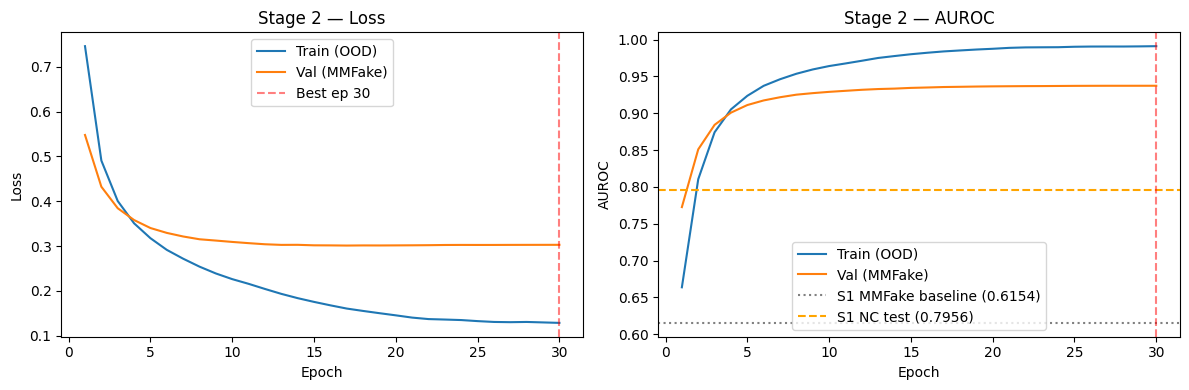

Figure saved: e:\eve-rag\paper\figures\stream_b_lora_stage2_training.png


In [25]:
import matplotlib.pyplot as plt

df_hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_hist['epoch'], df_hist['tr_loss'], label='Train (OOD)')
axes[0].plot(df_hist['epoch'], df_hist['vl_loss'], label='Val (MMFake)')
axes[0].axvline(best_epoch, color='red', linestyle='--', alpha=0.5, label=f'Best ep {best_epoch}')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Stage 2 — Loss'); axes[0].legend()

axes[1].plot(df_hist['epoch'], df_hist['tr_auc'], label='Train (OOD)')
axes[1].plot(df_hist['epoch'], df_hist['vl_auc'], label='Val (MMFake)')
axes[1].axhline(0.6154, color='gray',   linestyle=':',  label='S1 MMFake baseline (0.6154)')
axes[1].axhline(0.7956, color='orange', linestyle='--', label='S1 NC test (0.7956)')
axes[1].axvline(best_epoch, color='red', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUROC')
axes[1].set_title('Stage 2 — AUROC'); axes[1].legend()

plt.tight_layout()
fig_path = ROOT / 'paper' / 'figures' / 'stream_b_lora_stage2_training.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved: {fig_path}")

## 10. Summary

In [26]:

s = summary
print("=" * 60)
print("STREAM B — lora_stage2.ipynb COMPLETE")
print("=" * 60)
print(f"  LR={LR} (low to preserve NC knowledge)")
print(f"  Best MM val AUROC : {s['best_mm_val_auroc']:.4f} at epoch {s['best_epoch']}")
print(f"  NC test AUROC     : {s['nc_test_auroc']:.4f}")
print(f"  VERITE AUROC      : {s['verite_auroc']:.4f} ({s['verite_protocol']})")
print(f"  MMFake AUROC      : {s['mmfake_auroc']:.4f} ({s['mmfake_protocol']}, n={s['mmfake_eval_n']})")
print()
print("Outputs unchanged:")
print("  cache/lora_stage2/best_stage2.pt")
print("  cache/lora_stage2/lora2_feats_*.pkl")
print("  cache/lora_stage2/training_history.pkl")
print("  cache/lora_stage2/stage2_summary.pkl")
print("  paper/figures/stream_b_lora_stage2_training.png")


STREAM B — lora_stage2.ipynb COMPLETE
  LR=5e-05 (low to preserve NC knowledge)
  Best MM val AUROC : 0.9374 at epoch 30
  NC test AUROC     : 0.7287
  VERITE AUROC      : 0.4826 (zero_shot_not_trained)
  MMFake AUROC      : 0.9374 (heldout_eval_mask_only, n=2000)

Outputs unchanged:
  cache/lora_stage2/best_stage2.pt
  cache/lora_stage2/lora2_feats_*.pkl
  cache/lora_stage2/training_history.pkl
  cache/lora_stage2/stage2_summary.pkl
  paper/figures/stream_b_lora_stage2_training.png
